# Notebook 05 — Encoding and Architecture Validation

**Track A · Soccer Event Transformer · Identity × Context project**

| Item | Content |
|---|---|
| **Research question (project level)** | When identity and context point to different actions, what does a trained model do? Track A trains and freezes the model; this notebook decides its final configuration. |
| **Purpose of this notebook** | Four controlled experiments, run in stages, each changing one thing: (1) player threshold T100 vs T300 vs T100-shuffled, (2) depth, (3) attention heads, (4) context length. The outcome is the frozen configuration. |
| **Test data** | Not used. Every decision is made on validation data. |

**Selection principle.** The goal is not the most accurate model at any cost. It is the **smallest configuration whose validation NLL is within noise of the best** (notebook 04, Section 2.5 defines "within noise"), subject to a size cap of at most 4 layers and 8 heads so that later exhaustive analysis stays feasible. Learning rate and weight decay stay fixed at the values selected in notebook 04 (3e-4 and 0.1), so each comparison changes only the variable under study.

**Why staged?** Testing every combination (thresholds × depths × heads × context lengths) would need hundreds of runs. Each stage fixes the result of the previous stage and varies one axis.

**What is not used for selection.** Nothing about how the model uses identity versus context. That question is the subject of the later mechanistic analysis, and selecting a model because it shows the effect under study would bias that analysis.

Authored by: Alisha Shaikh (PICT, Pune)

In [1]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every Track A notebook)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# PROJECT_DIR holds code (src/), data artifacts, runs, results and the release.
PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
# DATASET_PATH is the prepared research dataset (one row per on-ball event).
DATASET_PATH = Path(os.environ.get("TRACK_A_DATASET", str(PROJECT_DIR / "data" / "cleaned_dataset.parquet")))
# RUN_MODE = "full"  -> real research runs (use this for every reported number)
# RUN_MODE = "smoke" -> tiny code check only; outputs go to PROJECT_DIR/smoke and are NOT results
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
(PROJECT_DIR / "src").mkdir(exist_ok=True)
(PROJECT_DIR / "tests").mkdir(exist_ok=True)

# Data-audit artifacts are cheap and always produced in full mode.
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
# Training runs, results and figures are separated by run mode so a smoke check can never
# overwrite or be confused with a research result.
OUTPUT_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
RUNS_DIR = OUTPUT_DIR / "runs"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURES_DIR = OUTPUT_DIR / "figures"
for folder in [ARTIFACTS_DIR, RUNS_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATASET_PATH:", DATASET_PATH, "| exists:", DATASET_PATH.exists())

Mounted at /content/drive
Colab: True | RUN_MODE: full
PROJECT_DIR: /content/drive/MyDrive/soccer_mi/track_a
DATASET_PATH: /content/drive/MyDrive/soccer_mi/track_a/data/cleaned_dataset.parquet | exists: True


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib
from scipy.stats import spearmanr
import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    # CPU training is correct but slow (about 0.55 s per step on one core, ~40-70 min per run).
    # It is allowed only on explicit request, and the device is recorded in every run's results.
    if os.environ.get("TRACK_A_ALLOW_CPU") != "1":
        raise RuntimeError("BLOCKED: full-mode training on CPU is very slow. Use a GPU runtime, "
                           "or set TRACK_A_ALLOW_CPU=1 to train on CPU deliberately.")
    print("WARNING: training on CPU by explicit request (TRACK_A_ALLOW_CPU=1).")
MANIFEST_PATH = OUTPUT_DIR / "manifests" / "experiment_manifest.jsonl"

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()
train_counts = data.count_train_events_per_player(events)
event_train_count = events["player_id"].map(train_counts).fillna(0).to_numpy()

with open(RESULTS_DIR / "04_selected_hyperparameters.json") as handle:
    selected_hyperparameters = json.load(handle)
LEARNING_RATE = selected_hyperparameters["learning_rate"]
WEIGHT_DECAY = selected_hyperparameters["weight_decay"]
EPOCH_BUDGET = selected_hyperparameters["epoch_budget"]
print(f"Selected in notebook 04: learning rate {LEARNING_RATE:g}, weight decay {WEIGHT_DECAY:g}, epoch budget {EPOCH_BUDGET}")

def transformer_config(seed, encoding, context_length=32, n_layers=4, n_heads=4, d_ff=512, use_groups=None):
    model = {"n_layers": n_layers, "n_heads": n_heads, "d_model": 128, "d_ff": d_ff}
    if use_groups is not None:
        model["use_groups"] = list(use_groups)
    return {"model_type": "transformer", "encoding": encoding, "possession_features": "pre_action",
            "context_length": context_length, "stride": 8, "seed": seed, "model": model,
            "training": {"learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "max_epochs": EPOCH_BUDGET}}

def run(config, keep_every_epoch=False):
    run_bundle = training.prepare_data(events, ARTIFACTS_DIR, config["encoding"], config["possession_features"],
                                       config["context_length"], config["stride"], DEVICE, RUN_MODE)
    result = training.train_run(config, run_bundle, RUNS_DIR, MANIFEST_PATH, keep_every_epoch=keep_every_epoch)
    return RUNS_DIR / result["run_name"]

def run_seeds(seeds, **settings):
    return [run(transformer_config(seed, **settings)) for seed in seeds]

Selected in notebook 04: learning rate 0.0003, weight decay 0.1, epoch budget 30


## Stage 1 — Player threshold: T100 vs T300 vs T100-shuffled

**Research question.** Does giving dedicated vectors to players with 100–299 training events improve prediction *because of player-specific information*, rather than merely because more events get some vector and the model has more parameters?

**Definitions (repeated here so this notebook stands alone).**

* **T300** — a player gets a dedicated learned 128-number vector if they have ≥ 300 training events; everyone else shares index 0, a fixed zero vector (no identity information).
* **T100** — the same with ≥ 100 training events (1,691 dedicated players instead of 350).
* **Band 100–299** — players with 100–299 training events: dedicated under T100, index 0 under T300.
* **T100-shuffled** — T100, but the player index of band events is randomly permuted among band events of the same split and role. Same number of vectors, same number of events per vector, but a vector no longer belongs to one player.

**Controls.** Same architecture, hyperparameters, data order rule and seeds {0, 1, 2}; only the player index differs.

**Metrics (validation).**

| Metric | Role |
|---|---|
| NLL on events of band 100–299 players | primary |
| NLL on events of players with ≥ 300 training events | guardrail (they are dedicated in all conditions) |
| Overall NLL | guardrail |
| Train − validation NLL gap on band events | overfitting check |
| Stability of per-player gains across seeds | are the gains a property of the players, or of seed luck? |

**Decision rule (fixed before running).** T100 is adopted only if **all** of the following hold; otherwise T300 is kept.

1. T100 beats T300 beyond noise on band events.
2. T100 beats T100-shuffled beyond noise on band events.
3. T300 does not beat T100 beyond noise on ≥ 300-event players.
4. T300 does not beat T100 beyond noise overall.
5. Per-player gains are stable across seeds: the mean Spearman correlation of per-player gains (T300 NLL − T100 NLL) between seed pairs is ≥ 0.3, using band players with ≥ 30 validation events. Both numbers are conventions of this study, not values derived from the data: 0.3 is a conventional lower bound for a "moderate" rank correlation, and 30 events keeps a per-player mean from being dominated by a few events.

*Spearman correlation*: a correlation between the *ranks* of two lists; 1 = identical ordering, 0 = no relation.

In [3]:
stage1_runs = {}
for encoding_name in ["T300", "T100", "T100_shuffled"]:
    stage1_runs[encoding_name] = run_seeds([0, 1, 2], encoding=encoding_name)

band_mask = (event_train_count >= 100) & (event_train_count < 300)
frequent_mask = event_train_count >= 300

stage1_comparisons = {
    "1. T100 vs T300, band 100-299": analysis.compare_conditions(stage1_runs["T100"], stage1_runs["T300"], targets, match_ids, band_mask),
    "2. T100 vs T100-shuffled, band 100-299": analysis.compare_conditions(stage1_runs["T100"], stage1_runs["T100_shuffled"], targets, match_ids, band_mask),
    "3. T300 vs T100, players >= 300": analysis.compare_conditions(stage1_runs["T300"], stage1_runs["T100"], targets, match_ids, frequent_mask),
    "4. T300 vs T100, all events": analysis.compare_conditions(stage1_runs["T300"], stage1_runs["T100"], targets, match_ids),
}
stage1_table = pd.DataFrame(stage1_comparisons).T[[
    "n_events", "nll_a_mean", "nll_b_mean", "difference_a_minus_b", "difference_ci_low", "difference_ci_high",
    "seeds_completely_separated", "a_better_beyond_noise"]]
stage1_table

[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.5487 | val NLL 1.0661 | val acc 0.5946 | val macro-F1 0.5145 | 10s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 0.9865 | val NLL 0.9570 | val acc 0.6030 | val macro-F1 0.5435 | 9s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9181 | val NLL 0.9338 | val acc 0.6107 | val macro-F1 0.5445 | 8s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.8899 | val NLL 0.9265 | val acc 0.6148 | val macro-F1 0.5407 | 9s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8680 | val NLL 0.9089 | val acc 0.6197 | val macro-F1 0.5450 | 10s
[transformer_T300_pre_action_L4_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8474 | val NLL 0.9224 | val acc 0.6112 | val macro-F1 0.5566 | 8s
[transformer_T

,n_events,nll_a_mean,nll_b_mean,difference_a_minus_b,difference_ci_low,difference_ci_high,seeds_completely_separated,a_better_beyond_noise
"1. T100 vs T300, band 100-299",20693,0.941686,0.914211,0.027476,0.021488,0.03321,False,False
"2. T100 vs T100-shuffled, band 100-299",20693,0.941686,0.952565,-0.010884,-0.016833,-0.004436,True,True
"3. T300 vs T100, players >= 300",13891,0.907704,0.918335,-0.010631,-0.015787,-0.006172,True,True
"4. T300 vs T100, all events",68003,0.914564,0.930349,-0.01579,-0.018706,-0.012941,True,True


In [4]:
# Condition 5: stability of per-player gains across seeds
val_rows_sorted, _ = analysis.load_val_event_nll(stage1_runs["T100"][0], targets)
val_player = events["player_id"].to_numpy()[val_rows_sorted]
band_players_in_val = pd.Series(val_player[band_mask[val_rows_sorted]]).value_counts()
eligible_players = band_players_in_val[band_players_in_val >= 30].index.to_numpy()

per_seed_gains = []
for seed_position in range(3):
    _, nll_T100 = analysis.load_val_event_nll(stage1_runs["T100"][seed_position], targets)
    _, nll_T300 = analysis.load_val_event_nll(stage1_runs["T300"][seed_position], targets)
    gain = pd.Series(nll_T300 - nll_T100).groupby(val_player).mean()
    per_seed_gains.append(gain.reindex(eligible_players).to_numpy())

pair_correlations = []
for first, second in [(0, 1), (0, 2), (1, 2)]:
    pair_correlations.append(spearmanr(per_seed_gains[first], per_seed_gains[second]).correlation)
mean_gain_correlation = float(np.mean(pair_correlations))

# Overfitting check on band events: train vs validation NLL (both scored once per event)
gap_rows = []
for encoding_name in ["T300", "T100", "T100_shuffled"]:
    train_values = []
    val_values = []
    for run_dir in stage1_runs[encoding_name]:
        train_file = np.load(run_dir / "train_event_nll.npz")
        train_band = band_mask[train_file["event_rows"]]
        train_values.append(train_file["nll"][train_band].mean())
        rows, nll = analysis.load_val_event_nll(run_dir, targets)
        val_values.append(nll[band_mask[rows]].mean())
    gap_rows.append({"encoding": encoding_name, "band train NLL": np.mean(train_values),
                     "band val NLL": np.mean(val_values), "gap (val - train)": np.mean(val_values) - np.mean(train_values)})
gap_table = pd.DataFrame(gap_rows).set_index("encoding").round(4)
print(f"Band players with >= 30 validation events: {len(eligible_players)}")
print("Spearman correlation of per-player gains between seed pairs:", [round(c, 3) for c in pair_correlations],
      f"-> mean {mean_gain_correlation:.3f}")
gap_table

Band players with >= 30 validation events: 221
Spearman correlation of per-player gains between seed pairs: [np.float64(0.388), np.float64(0.328), np.float64(0.233)] -> mean 0.317


,band train NLL,band val NLL,gap (val - train)
encoding,,,
T300,0.8488,0.9142,0.0654
T100,0.8308,0.9417,0.1109
T100_shuffled,0.8486,0.9526,0.1040


In [5]:
conditions = {
    "1. T100 beats T300 on band": stage1_comparisons["1. T100 vs T300, band 100-299"]["a_better_beyond_noise"],
    "2. T100 beats T100-shuffled on band": stage1_comparisons["2. T100 vs T100-shuffled, band 100-299"]["a_better_beyond_noise"],
    "3. T300 does not beat T100 on >=300 players": not stage1_comparisons["3. T300 vs T100, players >= 300"]["a_better_beyond_noise"],
    "4. T300 does not beat T100 overall": not stage1_comparisons["4. T300 vs T100, all events"]["a_better_beyond_noise"],
    "5. per-player gains stable (mean Spearman >= 0.3, PROVISIONAL)": mean_gain_correlation >= 0.3,
}
CHOSEN_ENCODING = "T100" if all(conditions.values()) else "T300"
for name, value in conditions.items():
    print(f"{'PASS' if value else 'FAIL'}  {name}")
print(f"\nStage 1 decision: {CHOSEN_ENCODING}")
training.save_json(RESULTS_DIR / "05_stage1_threshold.json", {
    "comparisons": stage1_comparisons, "gain_correlations": pair_correlations,
    "mean_gain_correlation": mean_gain_correlation, "eligible_players": int(len(eligible_players)),
    "train_val_gap": gap_table.reset_index().to_dict(orient="records"),
    "conditions": conditions, "decision": CHOSEN_ENCODING})

FAIL  1. T100 beats T300 on band
PASS  2. T100 beats T100-shuffled on band
FAIL  3. T300 does not beat T100 on >=300 players
FAIL  4. T300 does not beat T100 overall
PASS  5. per-player gains stable (mean Spearman >= 0.3, PROVISIONAL)

Stage 1 decision: T300


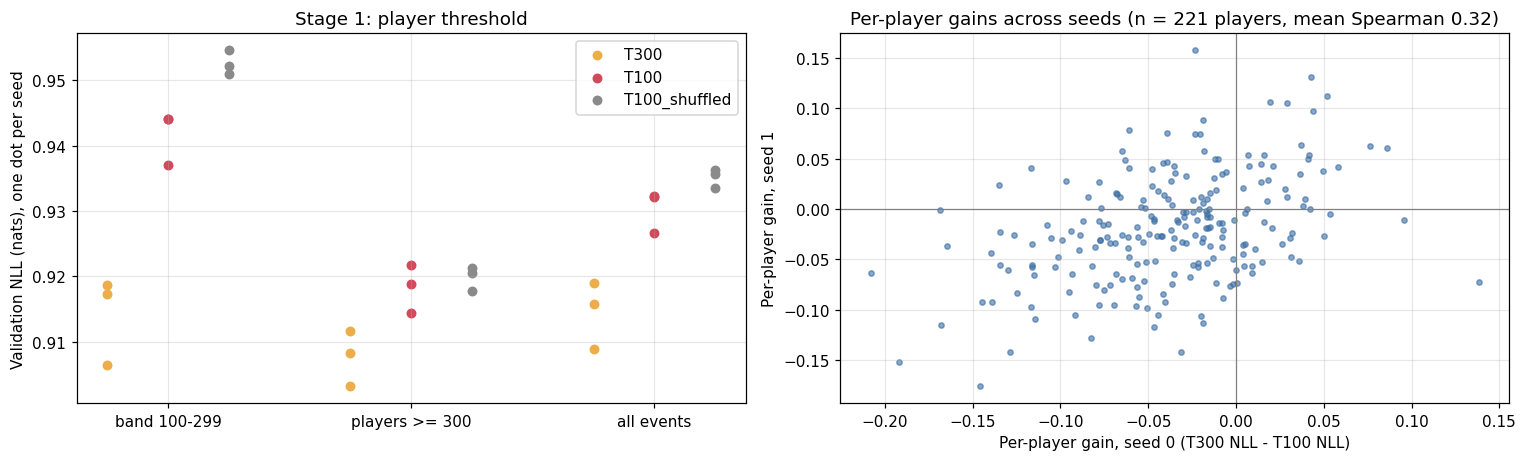

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
subsets = [("band 100-299", band_mask), ("players >= 300", frequent_mask), ("all events", None)]
colours = {"T300": "#edae49", "T100": "#d1495b", "T100_shuffled": "#8a8a8a"}
for subset_position, (subset_name, mask) in enumerate(subsets):
    for encoding_position, encoding_name in enumerate(["T300", "T100", "T100_shuffled"]):
        rows, nll_matrix = analysis.condition_event_nll(stage1_runs[encoding_name], targets)
        keep = np.ones(len(rows), dtype=bool) if mask is None else mask[rows]
        seed_values = nll_matrix[:, keep].mean(axis=1)
        x = subset_position + (encoding_position - 1) * 0.25
        axes[0].scatter(np.full(3, x), seed_values, color=colours[encoding_name], s=30,
                        label=encoding_name if subset_position == 0 else None)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels([name for name, _ in subsets])
axes[0].set_ylabel("Validation NLL (nats), one dot per seed")
axes[0].set_title("Stage 1: player threshold")
axes[0].legend()

axes[1].scatter(per_seed_gains[0], per_seed_gains[1], s=12, alpha=0.6, color="#3b6ea5")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].axvline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("Per-player gain, seed 0 (T300 NLL - T100 NLL)")
axes[1].set_ylabel("Per-player gain, seed 1")
axes[1].set_title(f"Per-player gains across seeds (n = {len(eligible_players)} players, "
                  f"mean Spearman {mean_gain_correlation:.2f})")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_stage1_threshold.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Left: validation NLL of each seed for T300, T100 and T100-shuffled, on three groups of events. Right: for each band player (100–299 training events) with at least 30 validation events, the change in NLL from T300 to T100 (T300 NLL − T100 NLL; positive means T100 is better) in seed 0 (x) and seed 1 (y).

**RESULT.**

* *T100 against T100-shuffled on band events.* T100 reaches 0.9417 and T100-shuffled 0.9526: a difference of −0.0109 nats (95% CI −0.0168 to −0.0044), with complete separation of the three seeds. T100 is better beyond noise (condition 2 passes).
* *T100 against T300 on band events.* T100 reaches 0.9417, T300 0.9142. On the very players for whom T100 adds a dedicated embedding, T100 is worse by 0.0275 nats (95% CI 0.0215 to 0.0332). Condition 1 fails.
* *Players with at least 300 training events.* T300 is better than T100 by 0.0106 nats (95% CI 0.0062 to 0.0158, seeds separated). Condition 3 fails: adding the band embeddings also degrades predictions for players who have a dedicated embedding in both encodings.
* *All validation events.* T300 is better by 0.0158 nats (95% CI 0.0129 to 0.0187, seeds separated). Condition 4 fails.
* *Overfitting check.* On band events, the gap between validation and training NLL is 0.1109 for T100 and 0.0654 for T300.
* *Per-player stability.* The Spearman correlations of per-player gains between seed pairs are 0.388, 0.328 and 0.233 (mean 0.317, from 221 players). Condition 5 passes.

**Interpretation.** T100 performs better than the shuffled condition, which indicates that the additional player identities contain player-specific predictive information: the embeddings do more than add capacity. Despite this signal, T100 has higher validation NLL than T300 on the band players, on the frequent players and overall. Most points in the right panel lie in the negative region, i.e. T300 predicts most band players better. The larger train–validation gap for T100 is consistent with the band embeddings, each learned from 100–299 events, fitting the training matches more closely than they generalise.

**Decision.** Three of the five pre-defined conditions fail, so T300 is retained. The choice follows from the pre-defined criteria and the recorded validation results, not from a preference for the smaller vocabulary.

**What cannot be concluded.** The comparison shows that, under this setup and training budget, the extra embeddings reduce overall predictive performance. It does not show that the information in them is unusable (the shuffled comparison indicates the opposite), and it does not show how the model uses identity.

## Stage 2 — Depth: 2 vs 4 layers (6 only if needed)

**Hypothesis.** Four layers learn predictive structure that two layers cannot. **Control:** chosen encoding, 4 heads, d_ff 512, K = 32. **Metric:** validation NLL. **Interpretation rule:** if 2 layers are within noise of 4, the 2-layer model is preferred (simpler to analyse). A 6-layer model is trained only if 4 layers beat 2 beyond noise, to check whether depth keeps helping; the size cap (≤ 4 layers) means a 6-layer result is reported but cannot be selected.

In [7]:
depth_runs = {2: run_seeds([0, 1, 2], encoding=CHOSEN_ENCODING, n_layers=2),
              4: run_seeds([0, 1, 2], encoding=CHOSEN_ENCODING, n_layers=4)}
four_vs_two = analysis.compare_conditions(depth_runs[4], depth_runs[2], targets, match_ids)
if four_vs_two["a_better_beyond_noise"]:
    depth_runs[6] = run_seeds([0, 1, 2], encoding=CHOSEN_ENCODING, n_layers=6)
    six_vs_four = analysis.compare_conditions(depth_runs[6], depth_runs[4], targets, match_ids)
    print("6 layers vs 4 layers (reported only; above the size cap):",
          {k: (round(v, 4) if isinstance(v, float) else v) for k, v in six_vs_four.items()})

CHOSEN_LAYERS_LABEL, depth_table = analysis.smallest_within_noise(
    [("2 layers", depth_runs[2]), ("4 layers", depth_runs[4])], targets, match_ids)
CHOSEN_LAYERS = int(CHOSEN_LAYERS_LABEL.split()[0])
print("Stage 2 decision:", CHOSEN_LAYERS_LABEL)
depth_table.to_csv(RESULTS_DIR / "05_stage2_depth.csv")
depth_table

[transformer_T300_pre_action_L2_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.6169 | val NLL 1.0730 | val acc 0.5919 | val macro-F1 0.5080 | 6s
[transformer_T300_pre_action_L2_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 0.9836 | val NLL 0.9590 | val acc 0.6017 | val macro-F1 0.5368 | 5s
[transformer_T300_pre_action_L2_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9212 | val NLL 0.9346 | val acc 0.6107 | val macro-F1 0.5415 | 5s
[transformer_T300_pre_action_L2_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.8921 | val NLL 0.9267 | val acc 0.6167 | val macro-F1 0.5502 | 6s
[transformer_T300_pre_action_L2_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8704 | val NLL 0.9143 | val acc 0.6183 | val macro-F1 0.5549 | 5s
[transformer_T300_pre_action_L2_H4_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8514 | val NLL 0.9240 | val acc 0.6128 | val macro-F1 0.5589 | 6s
[transformer_T30

,mean val NLL,is best,best beats it beyond noise,best - candidate (CI),seeds separated
candidate,,,,,
2 layers,0.9165,False,False,"-0.0019 [-0.0037, -0.0002]",False
4 layers,0.9146,True,False,NaN,NaN


**RESULT.** The 4-layer model reaches a mean validation NLL of 0.9146 (seed SD 0.0052), the 2-layer model 0.9165 (seed SD 0.0020). The 95% bootstrap interval of the difference, −0.0037 to −0.0002, excludes zero, but the per-seed results overlap, so the difference does not meet the decision rule. Under the rule, the smaller 2-layer model is retained, and the 6-layer model was not trained.

**Interpretation.** Doubling the depth gives at most a small improvement in NLL, and the 4-layer model varies more between seeds. The experiment does not provide sufficient evidence that the additional depth improves next-action prediction in this configuration.

## Stage 3 — Attention heads: 2 × 64 vs 4 × 32 vs 8 × 16

**Hypothesis.** How the 128-dimensional attention width is divided into heads changes how many separate "where to look" rules a layer has, but not necessarily prediction quality. **Control:** d_model stays 128, so total attention width and parameter count are identical across the three options. **Interpretation rule:** prefer the fewest heads within noise of the best (fewer heads = fewer components to examine later).

In [8]:
head_runs = {}
for n_heads in [2, 4, 8]:
    head_runs[n_heads] = run_seeds([0, 1, 2], encoding=CHOSEN_ENCODING, n_layers=CHOSEN_LAYERS, n_heads=n_heads)
chosen_heads_label, head_table = analysis.smallest_within_noise(
    [("2 heads x 64", head_runs[2]), ("4 heads x 32", head_runs[4]), ("8 heads x 16", head_runs[8])], targets, match_ids)
CHOSEN_HEADS = int(chosen_heads_label.split()[0])
print("Stage 3 decision:", chosen_heads_label)
head_table.to_csv(RESULTS_DIR / "05_stage3_heads.csv")
head_table

[transformer_T300_pre_action_L2_H2_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.6138 | val NLL 1.0645 | val acc 0.5925 | val macro-F1 0.5113 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 0.9833 | val NLL 0.9578 | val acc 0.6038 | val macro-F1 0.5409 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9215 | val NLL 0.9349 | val acc 0.6103 | val macro-F1 0.5367 | 6s
[transformer_T300_pre_action_L2_H2_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.8920 | val NLL 0.9234 | val acc 0.6188 | val macro-F1 0.5507 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8702 | val NLL 0.9133 | val acc 0.6181 | val macro-F1 0.5553 | 6s
[transformer_T300_pre_action_L2_H2_D128_F512_K32_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8506 | val NLL 0.9228 | val acc 0.6137 | val macro-F1 0.5555 | 5s
[transformer_T30

,mean val NLL,is best,best beats it beyond noise,best - candidate (CI),seeds separated
candidate,,,,,
2 heads x 64,0.9166,False,False,"-0.0001 [-0.0021, +0.0018]",False
4 heads x 32,0.9165,True,False,NaN,NaN
8 heads x 16,0.9196,False,False,"-0.0031 [-0.0048, -0.0014]",False


**RESULT.** At 2 layers and K = 32, 2 heads reach 0.9166, 4 heads 0.9165 and 8 heads 0.9196. No configuration is better than another beyond noise: the difference to 8 heads (−0.0031, CI −0.0048 to −0.0014) excludes zero, but the seeds overlap. Under the rule, the configuration with the fewest heads (2 heads of dimension 64) is retained.

**Interpretation.** The division of the 128 attention dimensions into heads changes validation NLL by at most 0.003 nats. Head count has little effect on predictive performance in this setting, so the choice can be made on the basis of simplicity for the later analysis.

## Stage 4 — Context length: K = 16 vs 32 vs 64

**Hypothesis.** History beyond the last 16 events (roughly two possessions) is used for prediction. **Control:** windows are rebuilt with the same rule (stride 8, never crossing a match or period); every validation event is still scored exactly once, in the window where it has the most history. **Metric:** validation NLL, plus NLL by position in the window (does more visible history lower the error?). **Interpretation rule:** the smallest K within noise of the best.

In [9]:
context_runs = {}
for context_length in [16, 32, 64]:
    context_runs[context_length] = run_seeds([0, 1, 2], encoding=CHOSEN_ENCODING, n_layers=CHOSEN_LAYERS,
                                             n_heads=CHOSEN_HEADS, context_length=context_length)
chosen_context_label, context_table = analysis.smallest_within_noise(
    [("K=16", context_runs[16]), ("K=32", context_runs[32]), ("K=64", context_runs[64])], targets, match_ids)
CHOSEN_CONTEXT = int(chosen_context_label.split("=")[1])
print("Stage 4 decision:", chosen_context_label)
context_table.to_csv(RESULTS_DIR / "05_stage4_context.csv")
context_table

[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  1 | train loss 1.6069 | val NLL 1.0869 | val acc 0.5865 | val macro-F1 0.5068 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  2 | train loss 1.0032 | val NLL 0.9585 | val acc 0.6047 | val macro-F1 0.5332 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  3 | train loss 0.9329 | val NLL 0.9315 | val acc 0.6116 | val macro-F1 0.5417 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  4 | train loss 0.9068 | val NLL 0.9223 | val acc 0.6138 | val macro-F1 0.5512 | 6s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  5 | train loss 0.8900 | val NLL 0.9142 | val acc 0.6191 | val macro-F1 0.5526 | 5s
[transformer_T300_pre_action_L2_H2_D128_F512_K16_g-all_lr0.0003_wd0.1_s0] epoch  6 | train loss 0.8768 | val NLL 0.9083 | val acc 0.6187 | val macro-F1 0.5567 | 5s
[transformer_T30

,mean val NLL,is best,best beats it beyond noise,best - candidate (CI),seeds separated
candidate,,,,,
K=16,0.9074,True,False,NaN,NaN
K=32,0.9166,False,True,"-0.0092 [-0.0108, -0.0077]",True
K=64,0.9299,False,True,"-0.0225 [-0.0251, -0.0200]",True


**RESULT.** At 2 layers and 2 heads, K = 16 reaches 0.9074, K = 32 0.9166 and K = 64 0.9299. K = 16 is better than K = 32 by 0.0092 nats (95% CI 0.0077 to 0.0108) and better than K = 64 by 0.0225 nats (95% CI 0.0200 to 0.0251); in both comparisons all seeds are separated. K = 16 is retained.

**Interpretation.** Context length has the largest effect of the three architectural variables tested, and shorter windows predict better. This is the opposite of what would be expected if history beyond 16 events carried substantial additional information. The figure below examines where the difference arises.

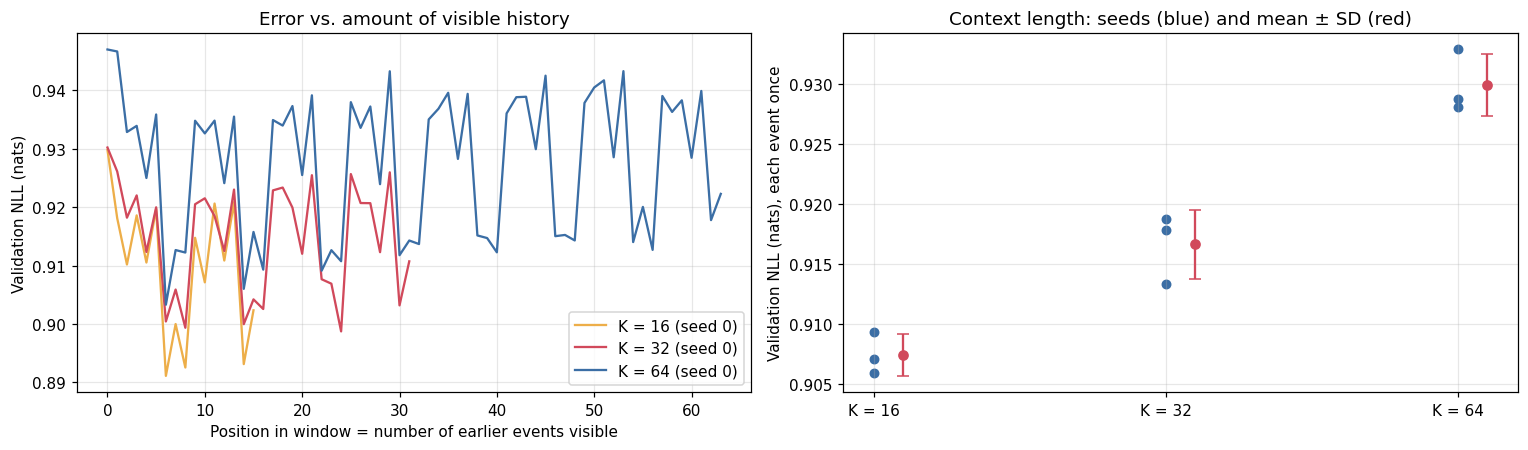

In [10]:
@torch.no_grad()
def nll_by_position(run_dir, context_length):
    """Validation NLL at every window position (all positions of the regular windows)."""
    run_bundle = training.prepare_data(events, ARTIFACTS_DIR, CHOSEN_ENCODING, "pre_action", context_length, 8, DEVICE, RUN_MODE)
    model = training.load_trained_model(run_dir, run_bundle)
    windows = data.build_windows(events, context_length, 8, split="val")
    if RUN_MODE == "smoke":
        windows = windows[:200]
    windows = torch.as_tensor(windows, device=DEVICE)
    totals = torch.zeros(context_length)
    for start in range(0, len(windows), 512):
        inputs, batch_targets = run_bundle["encoded"].batch(windows[start:start + 512])
        log_probabilities = torch.log_softmax(model(inputs), dim=-1)
        nll = -log_probabilities.gather(-1, batch_targets.unsqueeze(-1)).squeeze(-1)
        totals += nll.sum(dim=0).cpu()
    return (totals / len(windows)).numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for context_length, colour in [(16, "#edae49"), (32, "#d1495b"), (64, "#3b6ea5")]:
    curve = nll_by_position(context_runs[context_length][0], context_length)
    axes[0].plot(np.arange(context_length), curve, color=colour, label=f"K = {context_length} (seed 0)")
axes[0].set_xlabel("Position in window = number of earlier events visible")
axes[0].set_ylabel("Validation NLL (nats)")
axes[0].set_title("Error vs. amount of visible history")
axes[0].legend()

for position, context_length in enumerate([16, 32, 64]):
    values = analysis.seed_summary(context_runs[context_length])["val NLL"].to_numpy()
    axes[1].scatter(np.full(3, position), values, color="#3b6ea5", s=30)
    axes[1].errorbar(position + 0.1, values.mean(), yerr=values.std(ddof=1), fmt="o", color="#d1495b", capsize=4)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(["K = 16", "K = 32", "K = 64"])
axes[1].set_ylabel("Validation NLL (nats), each event once")
axes[1].set_title("Context length: seeds (blue) and mean ± SD (red)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_stage4_context.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Left: validation NLL at each position of the window for seed 0 of each context length; position *i* has *i* earlier events visible. Right: overall validation NLL (each event scored once, with maximal history) for each context length.

**Observation.** For all three models, NLL drops over roughly the first six positions and does not decrease systematically afterwards. The K = 64 curve lies above the K = 16 and K = 32 curves at almost every position, including the early positions where all three models see the same number of earlier events. All curves show a regular oscillation with a period of about eight positions, which matches the window stride of 8; its origin is not examined here.

**Interpretation.** Most of the usable history lies in the last few events. Because the K = 64 model is also worse at early positions, its higher overall NLL is not explained by the amount of history available at prediction time. It is consistent with the longer windows making training less effective under the fixed learning rate and epoch budget, but the experiment does not isolate the cause.

**What cannot be concluded.** A flat curve does not show that attention ignores distant events, only that attending to them does not lower prediction error on average.

## Summary figure: all architecture candidates

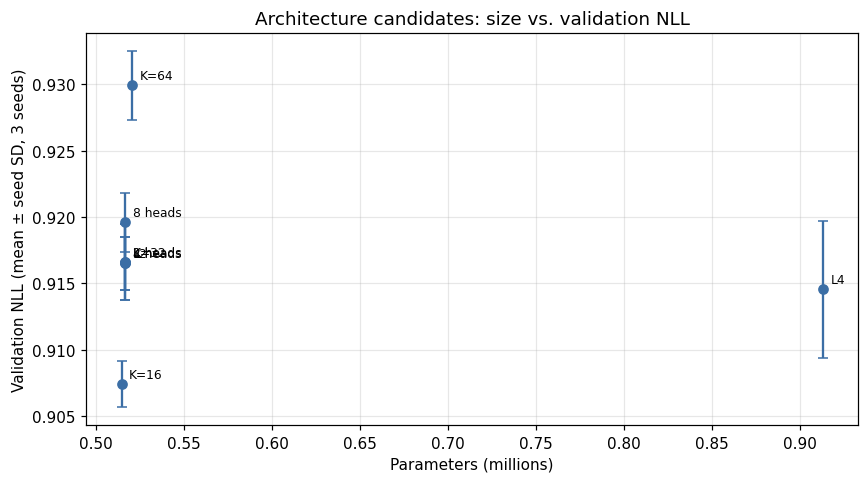

,candidate,parameters,mean val NLL,seed SD
0,L2,516623,0.9165,0.0020
1,L4,913167,0.9146,0.0052
2,2 heads,516623,0.9166,0.0029
3,4 heads,516623,0.9165,0.0020
4,8 heads,516623,0.9196,0.0022
5,K=16,514575,0.9074,0.0017
6,K=32,516623,0.9166,0.0029
7,K=64,520719,0.9299,0.0026


In [11]:
all_candidates = []
for label, run_dirs in ([(f"L{k}", v) for k, v in depth_runs.items()] + [(f"{k} heads", v) for k, v in head_runs.items()]
                        + [(f"K={k}", v) for k, v in context_runs.items()]):
    summary = analysis.seed_summary(run_dirs)
    parameters = analysis.load_final_results(run_dirs[0])["parameter_counts"]["total"]
    all_candidates.append({"candidate": label, "parameters": parameters,
                           "mean val NLL": summary["val NLL"].mean(), "seed SD": summary["val NLL"].std(ddof=1)})
candidate_table = pd.DataFrame(all_candidates).drop_duplicates("candidate")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(candidate_table["parameters"] / 1e6, candidate_table["mean val NLL"], yerr=candidate_table["seed SD"],
            fmt="o", capsize=3, color="#3b6ea5")
for _, row in candidate_table.iterrows():
    ax.annotate(row["candidate"], (row["parameters"] / 1e6, row["mean val NLL"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("Parameters (millions)")
ax.set_ylabel("Validation NLL (mean ± seed SD, 3 seeds)")
ax.set_title("Architecture candidates: size vs. validation NLL")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_size_vs_nll.png", bbox_inches="tight")
plt.show()
candidate_table.round(4)

**What the figure shows.** Every architecture candidate from stages 2–4: parameter count against mean validation NLL, with seed standard deviation as error bars.

**Observation.** The 2-layer candidates lie at about 0.52 million parameters and the 4-layer candidate at 0.91 million. The lowest NLL belongs to K = 16 at 2 layers. The 4-layer candidate has a lower mean NLL than the 2-layer candidates at K = 32 but the widest error bar, and it does not reach the K = 16 model.

**Interpretation.** Within the tested range, the additional parameters of the 4-layer model buy less than the change of context length. Head-count variants have identical parameter counts and sit at the same x position. The formal decision in each stage used the decision rule of notebook 04, Section 2.5.

## Freezing the configuration

The decisions above are written to a configuration file. From this point on the configuration is not changed, and only then can the test split be used (notebook 06).

In [12]:
import src.data as data_module
frozen_config = {
    "encoding": CHOSEN_ENCODING,
    "possession_features": "pre_action",
    "context_length": CHOSEN_CONTEXT,
    "stride": 8,
    "model": {"n_layers": CHOSEN_LAYERS, "n_heads": CHOSEN_HEADS, "d_model": 128, "d_ff": 512},
    "training": {"learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "max_epochs": EPOCH_BUDGET,
                 "batch_size": 256, "warmup_fraction": 0.05, "min_lr_ratio": 0.1, "grad_clip": 1.0, "patience": 5},
    "decisions": {"stage1_threshold": CHOSEN_ENCODING, "stage2_depth": CHOSEN_LAYERS_LABEL,
                  "stage3_heads": chosen_heads_label, "stage4_context": chosen_context_label},
    "selection_rule": "smallest configuration within noise of the best validation NLL (notebook 04, Section 2.5); "
                      "size cap <= 4 layers, <= 8 heads",
    "dataset_sha256": json.load(open(ARTIFACTS_DIR / "dataset_hash.json"))["sha256"],
    "run_mode": RUN_MODE,
    "frozen_at": pd.Timestamp.now(tz="UTC").isoformat(),
}
config_dir = OUTPUT_DIR / "config"
config_dir.mkdir(parents=True, exist_ok=True)
frozen_path = config_dir / "frozen_config.json"
if frozen_path.exists():
    existing = json.load(open(frozen_path))
    comparable_keys = ["encoding", "possession_features", "context_length", "model", "training"]
    if any(existing[key] != frozen_config[key] for key in comparable_keys):
        raise RuntimeError("A different frozen configuration already exists. It is not overwritten.")
    print("Frozen configuration already exists and matches; kept unchanged.")
else:
    training.save_json(frozen_path, frozen_config)
    print("Configuration frozen:", frozen_path)
print(json.dumps({key: frozen_config[key] for key in ["encoding", "context_length", "model", "training", "decisions"]}, indent=2))

Configuration frozen: /content/drive/MyDrive/soccer_mi/track_a/config/frozen_config.json
{
  "encoding": "T300",
  "context_length": 16,
  "model": {
    "n_layers": 2,
    "n_heads": 2,
    "d_model": 128,
    "d_ff": 512
  },
  "training": {
    "learning_rate": 0.0003,
    "weight_decay": 0.1,
    "max_epochs": 30,
    "batch_size": 256,
    "warmup_fraction": 0.05,
    "min_lr_ratio": 0.1,
    "grad_clip": 1.0,
    "patience": 5
  },
  "decisions": {
    "stage1_threshold": "T300",
    "stage2_depth": "2 layers",
    "stage3_heads": "2 heads x 64",
    "stage4_context": "K=16"
  }
}


## Summary

| Stage | Question | Decision rule | Result |
|---|---|---|---|
| 1 | Does T100 add player-specific information that improves prediction? | all five conditions, else T300 | T100 beats T100-shuffled on band players, but is worse than T300 on band players, on frequent players and overall → **T300** |
| 2 | Is 4-layer depth needed? | smallest within noise | 4 layers 0.9146 vs 2 layers 0.9165, not beyond noise → **2 layers** |
| 3 | How many heads? | fewest within noise | differences ≤ 0.003 nats, not beyond noise → **2 heads × 64** |
| 4 | How much history? | smallest K within noise | K = 16 better than K = 32 and K = 64 beyond noise → **K = 16** |

The frozen configuration is 2 layers, 2 heads, d_model 128, d_ff 512, K = 16, encoding T300.

**Limitations.** Each stage fixes earlier choices, so interactions between axes (for example, whether depth matters more at K = 16) are not tested; in particular, head count and context length were varied only at 2 layers. Learning rate and weight decay were tuned only for the base configuration. Three seeds give a coarse estimate of training noise. The frozen configuration should therefore not be read as a global optimum.